# Notebook 05 — Dataset Analysis

**Project:** Do AI Agents Know Which Actions Cannot Be Undone?  
**Purpose:** Perform a reproducible, read-only analysis of the authoritative NB4 v2 datasets before human annotation and model experiments.

This notebook analyses:
- dataset size, schema, class balance, and environment composition;
- H1/H2/H3 label distributions;
- action-family / operation coverage;
- minimal-pair integrity and duplicate / missing-data checks;
- grouped train/test split integrity and leakage;
- dataset limitations and an NB5 report.

**Source of truth:** `NB4_v2_snapshot_20261118T194353Z`, created by NB4 v2 and verified in both Drive roots. NB5 does not regenerate, relabel, or modify NB4 datasets. It writes its own timestamped analysis outputs and backups.

## 1. Project setup and reproducibility

Run all cells from top to bottom in a fresh Colab runtime. The notebook mounts Drive, resolves the exact NB4 v2 snapshot, and creates a separate NB5 output area. It never reads the obsolete NB4 v1 snapshots or the legacy `irrev_backup` directory.

In [3]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
import hashlib, json, os, shutil, math, re, statistics, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261119
np.random.seed(SEED)

PROJECT_ROOT = Path("/content/irrev")
DRIVE_ROOT = Path("/content/drive/MyDrive/ir")
BACKUP_ROOT = Path("/content/drive/MyDrive/ir_final")
NB4_SNAPSHOT_NAME = "NB4_v2_snapshot_20261118T194353Z"

LOCAL_NB5_ROOT = PROJECT_ROOT / "nb05_dataset_analysis"
REPORT_DIR = PROJECT_ROOT / "reports" / "nb05_dataset_analysis"
FIGURE_DIR = REPORT_DIR / "figures"
TABLE_DIR = REPORT_DIR / "tables"

for p in (LOCAL_NB5_ROOT, REPORT_DIR, FIGURE_DIR, TABLE_DIR):
    p.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("NB5 output root:", LOCAL_NB5_ROOT)
print("Report directory:", REPORT_DIR)
print("Random seed:", SEED)

Project root: /content/irrev
NB5 output root: /content/irrev/nb05_dataset_analysis
Report directory: /content/irrev/reports/nb05_dataset_analysis
Random seed: 20261119


## 2. Mount Google Drive and resolve the authoritative NB4 v2 snapshot

The snapshot is expected in both `/ir` and `/ir_final`. The main copy is preferred; the independent backup is used only if the main copy is unavailable. The selected files are checked against the NB4 reproducibility manifest and the two copies are not merged.

In [4]:
from google.colab import drive
drive.mount("/content/drive")

# Latest verified NB4 v2 snapshot
NB4_SNAPSHOT_NAME = "NB4_v2_snapshot_20261123T130007318638Z"

SNAPSHOT_CANDIDATES = [
    DRIVE_ROOT / NB4_SNAPSHOT_NAME,
    BACKUP_ROOT / NB4_SNAPSHOT_NAME,
]

required_files = [
    "sandbox_pairs_v2.jsonl",
    "sandbox_manifest_v2.json",
    "integrated_dataset_v2.jsonl",
    "scienceworld_unlabelled_candidates_v2.jsonl",
    "grouped_splits_v2.json",
    "NB4_dataset_summary_v2.json",
    "NB4_DATA_CARD_v2.md",
    "NB4_reproducibility_manifest_v2.json",
]

SNAPSHOT_DIR = next(
    (p for p in SNAPSHOT_CANDIDATES if p.is_dir()),
    None
)

if SNAPSHOT_DIR is None:
    raise FileNotFoundError(
        "Latest authoritative NB4 snapshot not found. Checked:\n"
        + "\n".join(str(p) for p in SNAPSHOT_CANDIDATES)
    )

missing = [
    name for name in required_files
    if not (SNAPSHOT_DIR / name).is_file()
]

if missing:
    raise FileNotFoundError(
        f"Snapshot is incomplete. Missing files: {missing}"
    )

print("Selected NB4 snapshot:", SNAPSHOT_DIR)
print("Files present:", len(required_files), "/", len(required_files))

for name in required_files:
    p = SNAPSHOT_DIR / name
    print(f"{name:48s} {p.stat().st_size:>12,} bytes")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Selected NB4 snapshot: /content/drive/MyDrive/ir/NB4_v2_snapshot_20261123T130007318638Z
Files present: 8 / 8
sandbox_pairs_v2.jsonl                              2,243,505 bytes
sandbox_manifest_v2.json                                  699 bytes
integrated_dataset_v2.jsonl                         2,249,352 bytes
scienceworld_unlabelled_candidates_v2.jsonl             6,510 bytes
grouped_splits_v2.json                                180,563 bytes
NB4_dataset_summary_v2.json                             3,907 bytes
NB4_DATA_CARD_v2.md                                     1,531 bytes
NB4_reproducibility_manifest_v2.json                    1,560 bytes


## 3. Load datasets and verify hashes

The analysis loads the 2,000-row Sandbox dataset and the integrated dataset separately. The unlabelled ScienceWorld candidate file is retained for provenance and coverage reporting, but is not treated as labelled training data.

In [5]:
def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

def read_jsonl(path):
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            if not line.strip():
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError as e:
                raise ValueError(f"Invalid JSONL at {path}, line {line_no}: {e}") from e
    return rows

def read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

SANDBOX_PATH = SNAPSHOT_DIR / "sandbox_pairs_v2.jsonl"
INTEGRATED_PATH = SNAPSHOT_DIR / "integrated_dataset_v2.jsonl"
UNLABELLED_PATH = SNAPSHOT_DIR / "scienceworld_unlabelled_candidates_v2.jsonl"
SPLITS_PATH = SNAPSHOT_DIR / "grouped_splits_v2.json"
SUMMARY_PATH = SNAPSHOT_DIR / "NB4_dataset_summary_v2.json"
NB4_MANIFEST_PATH = SNAPSHOT_DIR / "NB4_reproducibility_manifest_v2.json"

sandbox_rows = read_jsonl(SANDBOX_PATH)
integrated_rows = read_jsonl(INTEGRATED_PATH)
unlabelled_rows = read_jsonl(UNLABELLED_PATH)
splits_obj = read_json(SPLITS_PATH)
nb4_summary = read_json(SUMMARY_PATH)
nb4_manifest = read_json(NB4_MANIFEST_PATH)

hash_checks = {
    "sandbox": sha256_file(SANDBOX_PATH) == nb4_manifest["sandbox_sha256"],
    "integrated": sha256_file(INTEGRATED_PATH) == nb4_manifest["integrated_sha256"],
    "splits": sha256_file(SPLITS_PATH) == nb4_manifest["splits_sha256"],
}
print("Loaded Sandbox rows:", len(sandbox_rows))
print("Loaded integrated rows:", len(integrated_rows))
print("Unlabelled ScienceWorld candidates:", len(unlabelled_rows))
print("NB4 manifest hash checks:", hash_checks)
if not all(hash_checks.values()):
    raise AssertionError("One or more NB4 source files do not match the NB4 manifest.")

Loaded Sandbox rows: 2000
Loaded integrated rows: 2001
Unlabelled ScienceWorld candidates: 1
NB4 manifest hash checks: {'sandbox': True, 'integrated': True, 'splits': True}


## 4. Schema inspection

This cell records the top-level and nested key structure and prints representative records. It is deliberately an inspection step: do not assume that every environment has identical metadata fields.

In [6]:
def key_paths(obj, prefix="", out=None, max_depth=4):
    if out is None:
        out = set()
    if max_depth < 0 or not isinstance(obj, dict):
        return out
    for k, v in obj.items():
        path = f"{prefix}.{k}" if prefix else str(k)
        out.add(path)
        if isinstance(v, dict):
            key_paths(v, path, out, max_depth - 1)
    return out

def schema_summary(rows, name):
    paths = set()
    for row in rows[:100]:
        paths |= key_paths(row)
    print(f"\n{name}: {len(rows)} records")
    print("Observed key paths:")
    for p in sorted(paths):
        print(" -", p)

schema_summary(sandbox_rows, "Sandbox dataset")
schema_summary(integrated_rows, "Integrated dataset")
schema_summary(unlabelled_rows, "Unlabelled ScienceWorld candidates")

print("\nSandbox sample:")
print(json.dumps(sandbox_rows[0], indent=2)[:6000] if sandbox_rows else "EMPTY")
print("\nIntegrated sample:")
print(json.dumps(integrated_rows[0], indent=2)[:6000] if integrated_rows else "EMPTY")
print("\nSplit file top-level type:", type(splits_obj).__name__)
print("Split file top-level keys:", list(splits_obj)[:30] if isinstance(splits_obj, dict) else "not a dict")


Sandbox dataset: 2000 records
Observed key paths:
 - action_text
 - environment
 - horizon
 - id
 - label
 - meta
 - meta.family
 - meta.label_scope
 - meta.labels_by_horizon
 - meta.labels_by_horizon.1
 - meta.labels_by_horizon.2
 - meta.labels_by_horizon.3
 - meta.pair_id
 - meta.pair_variant
 - meta.recovery_depths_by_horizon
 - meta.recovery_depths_by_horizon.1
 - meta.recovery_depths_by_horizon.1.approximate_depth
 - meta.recovery_depths_by_horizon.1.exact_depth
 - meta.recovery_depths_by_horizon.2
 - meta.recovery_depths_by_horizon.2.approximate_depth
 - meta.recovery_depths_by_horizon.2.exact_depth
 - meta.recovery_depths_by_horizon.3
 - meta.recovery_depths_by_horizon.3.approximate_depth
 - meta.recovery_depths_by_horizon.3.exact_depth
 - meta.scenario_id
 - meta.spec
 - meta.spec.amount
 - meta.spec.changed_value
 - meta.spec.family
 - meta.spec.original_value
 - meta.spec.recovery_enabled
 - meta.spec.recovery_quality
 - meta.spec.recovery_steps
 - meta.spec.scenario_id
 - m

## 5. Core dataset counts and class balance

NB4 H3 labels are the primary labels in the integrated dataset. H1/H2/H3 are alternate bounded-recovery horizons for the same Sandbox scenarios; they are not independent examples and must not be added to the primary row count.

Dataset counts
{'sandbox_records': 2000, 'integrated_records': 2001, 'unlabelled_candidates': 1, 'environment_counts': {'python_sandbox': 2000, 'scienceworld': 1}}


,dataset,reversible,partially_reversible,irreversible,total
0,Sandbox (H3),750,250,1000,2000
1,Integrated (H3),751,250,1000,2001


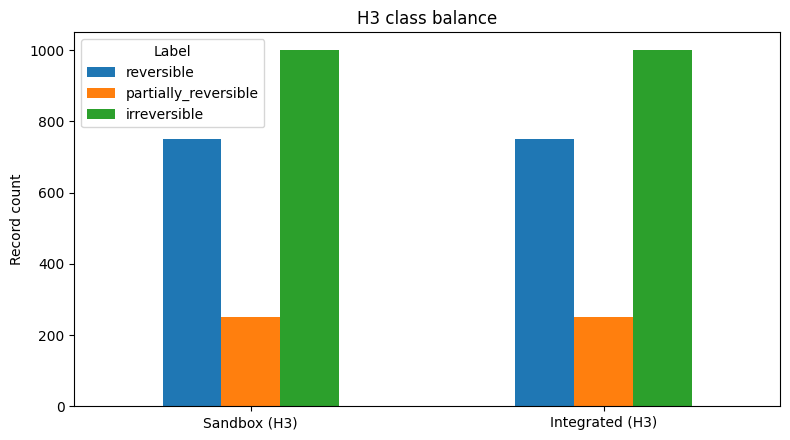

In [7]:
LABELS = ["reversible", "partially_reversible", "irreversible"]

def value_at(row, *paths, default=None):
    for path in paths:
        cur = row
        ok = True
        for part in path.split("."):
            if isinstance(cur, dict) and part in cur:
                cur = cur[part]
            else:
                ok = False
                break
        if ok and cur is not None:
            return cur
    return default

def count_values(values):
    return dict(Counter(str(v) for v in values if v is not None))

sandbox_labels = [r.get("label") for r in sandbox_rows]
integrated_labels = [r.get("label") for r in integrated_rows]
environment_counts = count_values(r.get("environment") for r in integrated_rows)

class_counts = pd.DataFrame([
    {"dataset": "Sandbox (H3)", **{k: Counter(sandbox_labels).get(k, 0) for k in LABELS}},
    {"dataset": "Integrated (H3)", **{k: Counter(integrated_labels).get(k, 0) for k in LABELS}},
])
class_counts["total"] = class_counts[LABELS].sum(axis=1)

print("Dataset counts")
print({
    "sandbox_records": len(sandbox_rows),
    "integrated_records": len(integrated_rows),
    "unlabelled_candidates": len(unlabelled_rows),
    "environment_counts": environment_counts,
})
display(class_counts)

fig, ax = plt.subplots(figsize=(8, 4.5))
class_counts.set_index("dataset")[LABELS].plot(kind="bar", ax=ax)
ax.set_title("H3 class balance")
ax.set_ylabel("Record count")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Label")
plt.tight_layout()
class_balance_png = FIGURE_DIR / "NB5_h3_class_balance.png"
fig.savefig(class_balance_png, dpi=160, bbox_inches="tight")
plt.show()

## 6. Horizon-specific label distributions

The Sandbox records contain `meta.labels_by_horizon`. This section computes H1, H2, and H3 counts directly from those fields and checks that each horizon accounts for the expected number of Sandbox records. It does not treat horizon views as extra rows.

label,irreversible,partially_reversible,reversible
horizon,,,
H1,1666,84,250
H2,1333,167,500
H3,1000,250,750


Missing horizon labels: {'1': 0, '2': 0, '3': 0}


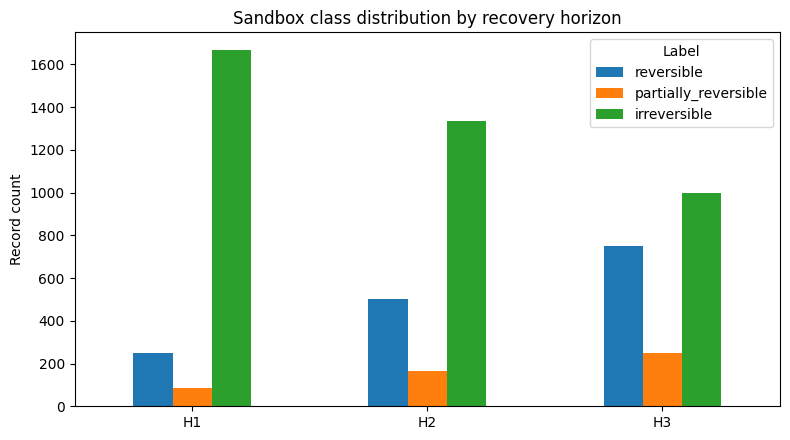

In [8]:
horizon_counts = {}
horizon_rows = []
for h in (1, 2, 3):
    counts = Counter()
    missing_h = 0
    for row in sandbox_rows:
        labels_by_h = value_at(row, "meta.labels_by_horizon", default={}) or {}
        label = labels_by_h.get(str(h), labels_by_h.get(h))
        if label is None:
            missing_h += 1
        else:
            counts[str(label)] += 1
    horizon_counts[str(h)] = dict(counts)
    for label in LABELS:
        horizon_rows.append({
            "horizon": f"H{h}",
            "label": label,
            "count": counts.get(label, 0),
            "missing": missing_h,
        })

horizon_df = pd.DataFrame(horizon_rows)
display(horizon_df.pivot(index="horizon", columns="label", values="count").fillna(0).astype(int))
print("Missing horizon labels:", {h: sum(1 for r in sandbox_rows
      if value_at(r, "meta.labels_by_horizon", default={}).get(h) is None)
      for h in ("1", "2", "3")})

fig, ax = plt.subplots(figsize=(8, 4.5))
pivot = horizon_df.pivot(index="horizon", columns="label", values="count").reindex(["H1", "H2", "H3"])
pivot[LABELS].plot(kind="bar", ax=ax)
ax.set_title("Sandbox class distribution by recovery horizon")
ax.set_ylabel("Record count")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Label")
plt.tight_layout()
horizon_png = FIGURE_DIR / "NB5_horizon_class_distribution.png"
fig.savefig(horizon_png, dpi=160, bbox_inches="tight")
plt.show()

## 7. Environment and action-family coverage

Environment counts are computed from the integrated records. Action-family / operation fields are extracted from the record metadata or specification when present. The notebook reports unavailable fields explicitly rather than inventing action categories.

Environment counts: {'python_sandbox': 2000, 'scienceworld': 1}
Action-family field coverage: 2000 / 2001
Operation field coverage: 0 / 2001
Action-family counts: {'edit': 500, 'delete': 500, 'email': 500, 'transfer': 500}
Operation counts: No operation field found


,action_family,records
0,edit,500
1,delete,500
2,email,500
3,transfer,500


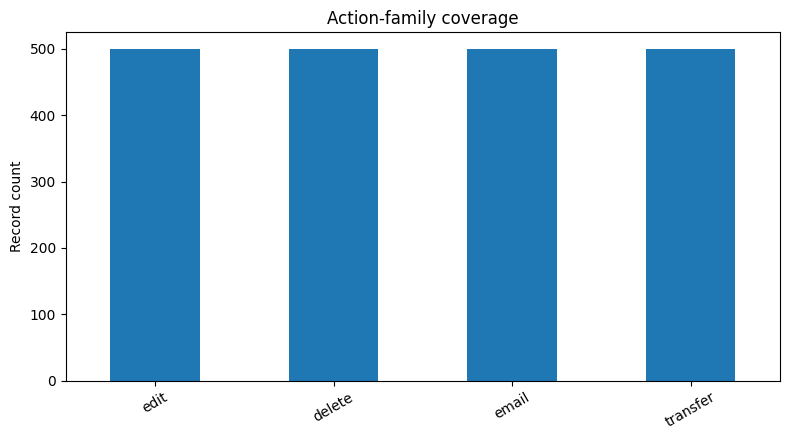

In [9]:
def get_spec(row):
    spec = row.get("spec")
    if isinstance(spec, dict):
        return spec
    meta = row.get("meta", {})
    if isinstance(meta, dict) and isinstance(meta.get("spec"), dict):
        return meta["spec"]
    return {}

def first_nonempty(*values):
    for v in values:
        if v is not None and str(v).strip() != "":
            return v
    return None

family_values, operation_values = [], []
for row in integrated_rows:
    spec = get_spec(row)
    meta = row.get("meta", {}) if isinstance(row.get("meta"), dict) else {}
    family = first_nonempty(
        spec.get("family"), meta.get("family"), row.get("action_family"),
        row.get("family"), row.get("action_type")
    )
    operation = first_nonempty(
        spec.get("operation"), spec.get("action"), meta.get("operation"),
        meta.get("action"), row.get("operation"), row.get("action")
    )
    family_values.append(family)
    operation_values.append(operation)

family_counts = Counter(str(x) for x in family_values if x is not None)
operation_counts = Counter(str(x) for x in operation_values if x is not None)

print("Environment counts:", environment_counts)
print("Action-family field coverage:", sum(x is not None for x in family_values), "/", len(integrated_rows))
print("Operation field coverage:", sum(x is not None for x in operation_values), "/", len(integrated_rows))
print("Action-family counts:", dict(family_counts) if family_counts else "No family field found")
print("Operation counts:", dict(operation_counts) if operation_counts else "No operation field found")

if family_counts:
    family_df = pd.DataFrame(family_counts.items(), columns=["action_family", "records"]).sort_values("records", ascending=False)
    display(family_df)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    family_df.set_index("action_family")["records"].plot(kind="bar", ax=ax)
    ax.set_title("Action-family coverage")
    ax.set_ylabel("Record count")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    family_png = FIGURE_DIR / "NB5_action_family_coverage.png"
    fig.savefig(family_png, dpi=160, bbox_inches="tight")
    plt.show()

## 8. Minimal-pair integrity

Sandbox pairs are grouped by `(environment, meta.scenario_id)`. The expected structure is two variants per scenario. Where the stored specification is available, the pair audit removes only `recovery_enabled` and checks whether the remaining specification is identical. This is an analysis-time integrity check; NB4 remains the generator and labelling source.

In [10]:
def scenario_key(row):
    env = row.get("environment")
    sid = value_at(row, "meta.scenario_id", "scenario_id", default=None)
    return (str(env), str(sid)) if sid is not None else None

pair_groups = defaultdict(list)
missing_pair_key = 0
for row in sandbox_rows:
    key = scenario_key(row)
    if key is None:
        missing_pair_key += 1
    else:
        pair_groups[key].append(row)

pair_size_counts = Counter(len(v) for v in pair_groups.values())
pair_bad_size = {str(k): n for k, n in pair_size_counts.items() if k != 2}

def spec_without_recovery_flag(row):
    spec = get_spec(row)
    if not spec:
        return None
    return {k: v for k, v in spec.items() if k != "recovery_enabled"}

spec_comparable = 0
spec_mismatch = 0
for key, group in pair_groups.items():
    if len(group) != 2:
        continue
    a, b = spec_without_recovery_flag(group[0]), spec_without_recovery_flag(group[1])
    if a is not None and b is not None:
        spec_comparable += 1
        if a != b:
            spec_mismatch += 1

pair_report = {
    "sandbox_rows": len(sandbox_rows),
    "scenario_groups": len(pair_groups),
    "missing_pair_key_rows": missing_pair_key,
    "pair_group_sizes": dict(pair_size_counts),
    "groups_not_exactly_two": sum(pair_bad_size.values()),
    "spec_comparable_pairs": spec_comparable,
    "spec_mismatched_pairs": spec_mismatch,
}
print(json.dumps(pair_report, indent=2))
if missing_pair_key or pair_bad_size:
    warnings.warn("Some Sandbox records do not form complete two-row scenario groups.")
if spec_comparable and spec_mismatch:
    warnings.warn("Some minimal pairs differ in fields beyond recovery_enabled.")

{
  "sandbox_rows": 2000,
  "scenario_groups": 1000,
  "missing_pair_key_rows": 0,
  "pair_group_sizes": {
    "2": 1000
  },
  "groups_not_exactly_two": 0,
  "spec_comparable_pairs": 1000,
  "spec_mismatched_pairs": 0
}


## 9. Missingness, duplicate IDs, and duplicate records

This section checks record identifiers, scenario keys, required top-level fields, and exact duplicate JSON records. It reports missing values without silently dropping rows.

In [11]:
def canonical_json(row):
    return json.dumps(row, sort_keys=True, ensure_ascii=False, separators=(",", ":"))

def duplicate_count(values):
    vals = [v for v in values if v is not None]
    return len(vals) - len(set(map(str, vals)))

def missing_top_level(rows, fields):
    return {field: sum(1 for r in rows if r.get(field) is None) for field in fields}

id_values = [first_nonempty(r.get("id"), r.get("record_id"), r.get("example_id")) for r in integrated_rows]
exact_row_strings = [canonical_json(r) for r in integrated_rows]

quality_report = {
    "integrated_missing_environment": sum(1 for r in integrated_rows if r.get("environment") is None),
    "integrated_missing_label": sum(1 for r in integrated_rows if r.get("label") is None),
    "integrated_missing_identifier": sum(1 for x in id_values if x is None),
    "duplicate_nonnull_identifiers": duplicate_count(id_values),
    "exact_duplicate_integrated_records": len(exact_row_strings) - len(set(exact_row_strings)),
    "sandbox_missing_scenario_id": sum(1 for r in sandbox_rows if scenario_key(r) is None),
    "sandbox_missing_horizon_labels": {
        str(h): sum(1 for r in sandbox_rows
                    if value_at(r, "meta.labels_by_horizon", default={}).get(str(h)) is None)
        for h in (1, 2, 3)
    },
}
print(json.dumps(quality_report, indent=2))

{
  "integrated_missing_environment": 0,
  "integrated_missing_label": 0,
  "integrated_missing_identifier": 0,
  "duplicate_nonnull_identifiers": 0,
  "exact_duplicate_integrated_records": 0,
  "sandbox_missing_scenario_id": 0,
  "sandbox_missing_horizon_labels": {
    "1": 0,
    "2": 0,
    "3": 0
  }
}


## 10. Label consistency and provenance checks

The integrated primary dataset should contain only the three scientific labels. The unlabelled ScienceWorld candidate is reported separately and must not appear as a labelled primary row. NB4 provenance is retained through the source manifest and dataset summary.

In [12]:
allowed_labels = set(LABELS)
observed_labels = set(str(x) for x in integrated_labels if x is not None)
unexpected_labels = sorted(observed_labels - allowed_labels)

unlabelled_in_primary = sum(
    1 for r in integrated_rows
    if str(r.get("label", "")).lower().startswith("unlabelled")
    or r.get("label") is None
)

provenance_report = {
    "allowed_primary_labels": sorted(allowed_labels),
    "observed_primary_labels": sorted(observed_labels),
    "unexpected_primary_labels": unexpected_labels,
    "unlabelled_or_missing_primary_rows": unlabelled_in_primary,
    "unlabelled_candidate_file_rows": len(unlabelled_rows),
    "nb3_source_path_recorded": nb4_summary.get("nb3_source"),
    "nb3_source_sha256_recorded": nb4_summary.get("nb3_source_sha256"),
    "nb4_generator_version": nb4_manifest.get("generator_version"),
    "nb4_seed": nb4_manifest.get("seed"),
}
print(json.dumps(provenance_report, indent=2))

{
  "allowed_primary_labels": [
    "irreversible",
    "partially_reversible",
    "reversible"
  ],
  "observed_primary_labels": [
    "irreversible",
    "partially_reversible",
    "reversible"
  ],
  "unexpected_primary_labels": [],
  "unlabelled_or_missing_primary_rows": 0,
  "unlabelled_candidate_file_rows": 1,
  "nb3_source_path_recorded": "/content/drive/MyDrive/ir/NB3_snapshot_20261123T123703377799Z/data/scienceworld/processed/scienceworld_pilot_canonical_20261123T123703338645Z.jsonl",
  "nb3_source_sha256_recorded": "4922ea13834b3090fae04cc1f6777c13c3c934c5d2ad20909700d199c9c707be",
  "nb4_generator_version": "2.0.0",
  "nb4_seed": 20261119
}


## 11. Grouped split structure and leakage audit

This section first displays the split-file structure. It then attempts a conservative parser for common split layouts. If the split representation is not recognized, it stops with a clear message rather than reporting a false “no leakage” result. The source split file remains unchanged.

In [14]:
print("Split metadata preview:")
print(json.dumps({
    "dataset_sha256": splits_obj.get("dataset_sha256"),
    "split_method": splits_obj.get("split_method"),
    "test_fraction": splits_obj.get("test_fraction"),
    "seeds": splits_obj.get("seeds"),
    "split_keys": list(splits_obj.get("splits", {}).keys())
}, indent=2))

# NB4 v2 structure:
# {
#   "splits": {
#       "0": {"train_ids": [...], "test_ids": [...]},
#       "1": {"train_ids": [...], "test_ids": [...]},
#       "2": {"train_ids": [...], "test_ids": [...]}
#   }
# }

if not isinstance(splits_obj, dict) or not isinstance(splits_obj.get("splits"), dict):
    raise ValueError("Unexpected grouped_splits_v2.json structure.")

split_audit = []

for seed, split_data in splits_obj["splits"].items():
    if not isinstance(split_data, dict):
        raise ValueError(f"Invalid split structure for seed {seed}.")

    if "train_ids" not in split_data or "test_ids" not in split_data:
        raise ValueError(f"Missing train_ids/test_ids for seed {seed}.")

    train_list = [str(x) for x in split_data["train_ids"]]
    test_list = [str(x) for x in split_data["test_ids"]]

    train_ids = set(train_list)
    test_ids = set(test_list)

    overlap = train_ids & test_ids
    duplicate_train = len(train_list) - len(train_ids)
    duplicate_test = len(test_list) - len(test_ids)

    split_audit.append({
        "seed": seed,
        "train_count": len(train_list),
        "test_count": len(test_list),
        "unique_train_ids": len(train_ids),
        "unique_test_ids": len(test_ids),
        "id_overlap": len(overlap),
        "duplicate_train_ids": duplicate_train,
        "duplicate_test_ids": duplicate_test,
        "train_test_id_leakage": bool(overlap),
    })

split_audit_df = pd.DataFrame(split_audit)
display(split_audit_df)

if split_audit_df["train_test_id_leakage"].any():
    raise AssertionError("Train/test ID leakage detected.")

if (split_audit_df["duplicate_train_ids"] > 0).any():
    raise AssertionError("Duplicate IDs found in training splits.")

if (split_audit_df["duplicate_test_ids"] > 0).any():
    raise AssertionError("Duplicate IDs found in test splits.")

print("ID-level train/test overlap and duplicate checks passed.")

Split metadata preview:
{
  "dataset_sha256": "0d890a39de3953e1a4d8f03d0cde7fad9a27ebba143e07c0b31482d8bb13c9bd",
  "split_method": "StratifiedGroupKFold_v2",
  "test_fraction": 0.2,
  "seeds": [
    0,
    1,
    2
  ],
  "split_keys": [
    "0",
    "1",
    "2"
  ]
}


,seed,train_count,test_count,unique_train_ids,unique_test_ids,id_overlap,duplicate_train_ids,duplicate_test_ids,train_test_id_leakage
0,0,1599,402,1599,402,0,0,0,False
1,1,1601,400,1601,400,0,0,0,False
2,2,1601,400,1601,400,0,0,0,False


ID-level train/test overlap and duplicate checks passed.


## 12. Scenario-group leakage audit

A grouped split must keep all records from a scenario in one partition. The audit maps split record IDs back to the integrated dataset and checks scenario-group overlap. If split entries cannot be mapped to dataset IDs, this section reports that limitation and does not claim the group-leakage test passed.

In [16]:
# Build record ID -> scenario group mapping
def row_identifier(row):
    return first_nonempty(
        row.get("id"),
        row.get("record_id"),
        row.get("example_id")
    )

id_to_group = {}

for row in integrated_rows:
    rid = row_identifier(row)
    gkey = scenario_key(row)

    if rid is not None and gkey is not None:
        id_to_group[str(rid)] = str(gkey)

# Audit the actual NB4 v2 split structure
group_audit = []

for seed, split_data in splits_obj["splits"].items():
    train_ids = {str(x) for x in split_data["train_ids"]}
    test_ids = {str(x) for x in split_data["test_ids"]}

    train_groups = {
        id_to_group[x] for x in train_ids if x in id_to_group
    }
    test_groups = {
        id_to_group[x] for x in test_ids if x in id_to_group
    }

    mapped_train = sum(x in id_to_group for x in train_ids)
    mapped_test = sum(x in id_to_group for x in test_ids)

    overlap_groups = train_groups & test_groups

    group_audit.append({
        "seed": seed,
        "train_ids_mapped": mapped_train,
        "test_ids_mapped": mapped_test,
        "train_group_count": len(train_groups),
        "test_group_count": len(test_groups),
        "overlapping_scenario_groups": len(overlap_groups),
        "group_leakage": bool(overlap_groups),
        "full_id_mapping": (
            mapped_train == len(train_ids)
            and mapped_test == len(test_ids)
        )
    })

group_audit_df = pd.DataFrame(group_audit)
display(group_audit_df)

if not group_audit_df["full_id_mapping"].all():
    raise AssertionError(
        "Some split IDs could not be mapped to integrated dataset records. "
        "Do not claim a complete scenario-group leakage audit."
    )

if group_audit_df["group_leakage"].any():
    raise AssertionError("Scenario-group leakage detected.")

print("Scenario-group leakage audit passed for all three seeds.")

,seed,train_ids_mapped,test_ids_mapped,train_group_count,test_group_count,overlapping_scenario_groups,group_leakage,full_id_mapping
0,0,1599,402,800,201,0,False,True
1,1,1601,400,801,200,0,False,True
2,2,1601,400,801,200,0,False,True


Scenario-group leakage audit passed for all three seeds.


## 13. Consolidated NB5 findings and limitations

This cell builds a concise machine-readable analysis summary. It distinguishes checks performed directly in NB5 from inherited NB4 provenance and avoids treating horizon views as independent samples.

In [17]:
nb5_summary = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "notebook": "05_dataset_analysis",
    "source_snapshot": str(SNAPSHOT_DIR),
    "source_manifest_hash": sha256_file(NB4_MANIFEST_PATH),
    "source_hash_checks": hash_checks,
    "record_counts": {
        "sandbox": len(sandbox_rows),
        "integrated": len(integrated_rows),
        "unlabelled_scienceworld_candidates": len(unlabelled_rows),
    },
    "integrated_environment_counts": environment_counts,
    "integrated_h3_class_counts": dict(Counter(str(x) for x in integrated_labels)),
    "sandbox_horizon_class_counts": horizon_counts,
    "action_family_counts": dict(family_counts),
    "operation_counts": dict(operation_counts),
    "minimal_pair_audit": pair_report,
    "data_quality": quality_report,
    "label_provenance": provenance_report,
    "split_id_audit": split_audit,
    "scenario_group_audit": group_audit,
    "limitations": [
        "H1, H2, and H3 are alternate bounded-recovery labels for the same Sandbox scenarios, not independent examples.",
        "The Sandbox is a deterministic rule-based in-memory simulation, not a real operating system or live service.",
        "Only one labelled ScienceWorld pilot record is present in the NB4 v2 integrated dataset; it is insufficient for ScienceWorld-only performance claims or cross-environment generalisation.",
        "The unlabelled ScienceWorld candidate is retained separately and excluded from the labelled primary dataset.",
        "Bounded recoverability within the declared action space and horizon does not establish absolute irreversibility.",
        "Action-family / operation coverage is reported only when those fields are present in the stored records.",
    ],
}
NB5_SUMMARY_JSON = REPORT_DIR / "NB5_dataset_analysis_summary.json"
with open(NB5_SUMMARY_JSON, "w", encoding="utf-8") as f:
    json.dump(nb5_summary, f, indent=2, ensure_ascii=False)
print("Saved:", NB5_SUMMARY_JSON)
print(json.dumps(nb5_summary, indent=2)[:16000])

Saved: /content/irrev/reports/nb05_dataset_analysis/NB5_dataset_analysis_summary.json
{
  "created_utc": "2026-11-23T13:07:21.743764+00:00",
  "notebook": "05_dataset_analysis",
  "source_snapshot": "/content/drive/MyDrive/ir/NB4_v2_snapshot_20261123T130007318638Z",
  "source_manifest_hash": "c00eccc3103b7e75ff42679df65a28dc0efd75fd4d1bf31da260d4f7f42ae12f",
  "source_hash_checks": {
    "sandbox": true,
    "integrated": true,
    "splits": true
  },
  "record_counts": {
    "sandbox": 2000,
    "integrated": 2001,
    "unlabelled_scienceworld_candidates": 1
  },
  "integrated_environment_counts": {
    "python_sandbox": 2000,
    "scienceworld": 1
  },
  "integrated_h3_class_counts": {
    "reversible": 751,
    "irreversible": 1000,
    "partially_reversible": 250
  },
  "sandbox_horizon_class_counts": {
    "1": {
      "reversible": 250,
      "irreversible": 1666,
      "partially_reversible": 84
    },
    "2": {
      "reversible": 500,
      "irreversible": 1333,
      "partia

## 14. Export analysis tables and data-quality report

All outputs are NB5-derived. NB4 input datasets and manifests are read-only.

In [18]:
class_counts.to_csv(TABLE_DIR / "NB5_h3_class_balance.csv", index=False)
horizon_df.to_csv(TABLE_DIR / "NB5_horizon_class_balance.csv", index=False)
pd.DataFrame([
    {"environment": k, "records": v} for k, v in environment_counts.items()
]).to_csv(TABLE_DIR / "NB5_environment_counts.csv", index=False)
split_audit_df.to_csv(TABLE_DIR / "NB5_split_id_audit.csv", index=False)
group_audit_df.to_csv(TABLE_DIR / "NB5_group_leakage_audit.csv", index=False)

report_lines = [
    "# NB5 — Dataset Analysis Report",
    "",
    f"- Created (UTC): {nb5_summary['created_utc']}",
    f"- Source snapshot: `{SNAPSHOT_DIR}`",
    f"- Sandbox records: {len(sandbox_rows):,}",
    f"- Integrated labelled records: {len(integrated_rows):,}",
    f"- Unlabelled ScienceWorld candidates: {len(unlabelled_rows):,}",
    "",
    "## H3 class counts",
]
for label, count in Counter(str(x) for x in integrated_labels).items():
    report_lines.append(f"- {label}: {count:,}")
report_lines += ["", "## Environment counts"]
for env, count in environment_counts.items():
    report_lines.append(f"- {env}: {count:,}")
report_lines += ["", "## Horizon class counts (Sandbox)"]
for h, counts in horizon_counts.items():
    report_lines.append(f"- H{h}: {counts}")
report_lines += [
    "",
    "## Minimal-pair audit",
    f"- Scenario groups: {pair_report['scenario_groups']:,}",
    f"- Groups not exactly two rows: {pair_report['groups_not_exactly_two']:,}",
    f"- Comparable specifications: {pair_report['spec_comparable_pairs']:,}",
    f"- Specification mismatches: {pair_report['spec_mismatched_pairs']:,}",
    "",
    "## Limitations",
]
report_lines += [f"- {item}" for item in nb5_summary["limitations"]]
NB5_REPORT_MD = REPORT_DIR / "NB5_DATASET_ANALYSIS_REPORT.md"
NB5_REPORT_MD.write_text("\n".join(report_lines) + "\n", encoding="utf-8")

print("Exported tables to:", TABLE_DIR)
print("Exported report:", NB5_REPORT_MD)
print("Figures:", list(FIGURE_DIR.glob("*.png")))

Exported tables to: /content/irrev/reports/nb05_dataset_analysis/tables
Exported report: /content/irrev/reports/nb05_dataset_analysis/NB5_DATASET_ANALYSIS_REPORT.md
Figures: [PosixPath('/content/irrev/reports/nb05_dataset_analysis/figures/NB5_horizon_class_distribution.png'), PosixPath('/content/irrev/reports/nb05_dataset_analysis/figures/NB5_h3_class_balance.png'), PosixPath('/content/irrev/reports/nb05_dataset_analysis/figures/NB5_action_family_coverage.png')]


## 15. NB5 validation checklist

The checklist is deliberately conservative. A check is marked passed only when the corresponding evidence is present. In particular, scenario-group leakage is not marked passed if split IDs cannot be mapped back to the integrated dataset.

In [19]:
checklist = {
    "nb4_source_hashes_match_manifest": bool(all(hash_checks.values())),
    "sandbox_record_count_matches_nb4_summary": len(sandbox_rows) == nb4_summary.get("sandbox_records"),
    "integrated_record_count_matches_nb4_summary": len(integrated_rows) == nb4_summary.get("integrated_records"),
    "primary_labels_are_allowed": len(unexpected_labels) == 0 and unlabelled_in_primary == 0,
    "all_sandbox_rows_have_scenario_keys": missing_pair_key == 0,
    "all_sandbox_scenarios_have_two_rows": len(pair_bad_size) == 0 and missing_pair_key == 0,
    "comparable_pair_specs_differ_only_by_recovery_flag": spec_comparable > 0 and spec_mismatch == 0,
    "split_id_leakage_absent": not split_audit_df["train_test_id_leakage"].any(),
    "scenario_group_leakage_absent_and_fully_mapped": bool(group_audit_df["full_id_mapping"].all() and not group_audit_df["group_leakage"].any()),
    "nb5_report_saved": NB5_REPORT_MD.exists(),
    "nb5_summary_saved": NB5_SUMMARY_JSON.exists(),
}
NB5_CHECKLIST_JSON = REPORT_DIR / "NB5_validation_checklist.json"
with open(NB5_CHECKLIST_JSON, "w", encoding="utf-8") as f:
    json.dump(checklist, f, indent=2)

print(json.dumps(checklist, indent=2))
print("\nPassed:", sum(checklist.values()), "/", len(checklist))
if not all(checklist.values()):
    print("NB5 status: REVIEW REQUIRED — inspect failed checks before proceeding.")
else:
    print("NB5 status: READY FOR REVIEW.")

{
  "nb4_source_hashes_match_manifest": true,
  "sandbox_record_count_matches_nb4_summary": true,
  "integrated_record_count_matches_nb4_summary": true,
  "primary_labels_are_allowed": true,
  "all_sandbox_rows_have_scenario_keys": true,
  "all_sandbox_scenarios_have_two_rows": true,
  "comparable_pair_specs_differ_only_by_recovery_flag": true,
  "split_id_leakage_absent": true,
  "scenario_group_leakage_absent_and_fully_mapped": true,
  "nb5_report_saved": true,
  "nb5_summary_saved": true
}

Passed: 11 / 11
NB5 status: READY FOR REVIEW.


## 16. Timestamped Drive backup and SHA-256 verification

The NB5 report, tables, figures, and validation checklist are copied into a new timestamped folder in both Drive roots. The notebook never overwrites an existing snapshot and does not delete any NB4 snapshot.

In [20]:
timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
NB5_SNAPSHOT_NAME = f"NB5_snapshot_{timestamp}"

outputs_to_backup = [
    NB5_SUMMARY_JSON,
    NB5_REPORT_MD,
    NB5_CHECKLIST_JSON,
    *TABLE_DIR.glob("*.csv"),
    *FIGURE_DIR.glob("*.png"),
]

backup_results = []
for root in (DRIVE_ROOT, BACKUP_ROOT):
    target = root / NB5_SNAPSHOT_NAME
    target.mkdir(parents=True, exist_ok=False)
    verified_files = []
    for src in outputs_to_backup:
        if not src.exists() or not src.is_file():
            continue
        dst = target / src.name
        shutil.copy2(src, dst)
        ok = (
            src.stat().st_size == dst.stat().st_size
            and sha256_file(src) == sha256_file(dst)
        )
        verified_files.append({
            "file": src.name,
            "bytes": dst.stat().st_size,
            "sha256": sha256_file(dst),
            "verified": ok,
        })
        if not ok:
            raise IOError(f"Backup verification failed: {dst}")
    backup_results.append({
        "root": str(root),
        "snapshot": str(target),
        "files_verified": len(verified_files),
        "all_verified": all(x["verified"] for x in verified_files),
        "files": verified_files,
    })


NB5_BACKUP_MANIFEST = REPORT_DIR / f"{NB5_SNAPSHOT_NAME}_manifest.json"
backup_manifest_obj = {
    "snapshot_name": NB5_SNAPSHOT_NAME,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "source_nb4_snapshot": str(SNAPSHOT_DIR),
    "checklist": checklist,
    "backups": backup_results,
}
with open(NB5_BACKUP_MANIFEST, "w", encoding="utf-8") as f:
    json.dump(backup_manifest_obj, f, indent=2)

# Store the manifest inside each snapshot and verify it too.
for result in backup_results:
    snapshot_dir = Path(result["snapshot"])
    manifest_copy = snapshot_dir / NB5_BACKUP_MANIFEST.name
    shutil.copy2(NB5_BACKUP_MANIFEST, manifest_copy)
    if sha256_file(NB5_BACKUP_MANIFEST) != sha256_file(manifest_copy):
        raise IOError(f"Backup manifest verification failed: {manifest_copy}")
    result["manifest"] = str(manifest_copy)
    result["manifest_verified"] = True

print(json.dumps(backup_results, indent=2))
assert all(x["all_verified"] and x["manifest_verified"] for x in backup_results)
print("\\nNB5 BACKUP VERIFIED IN BOTH DRIVE ROOTS.")
print("Snapshot name:", NB5_SNAPSHOT_NAME)


[
  {
    "root": "/content/drive/MyDrive/ir",
    "snapshot": "/content/drive/MyDrive/ir/NB5_snapshot_20261123T130730Z",
    "files_verified": 11,
    "all_verified": true,
    "files": [
      {
        "file": "NB5_dataset_analysis_summary.json",
        "bytes": 4956,
        "sha256": "a899201e8442b51b96974bb13d8e991399f8327b9c971f0cd3772466aea7f2e0",
        "verified": true
      },
      {
        "file": "NB5_DATASET_ANALYSIS_REPORT.md",
        "bytes": 1598,
        "sha256": "77eb47743d95fdbd0c36621a3430acefcb5704cb46877a04eecf2d5ef66d2cc3",
        "verified": true
      },
      {
        "file": "NB5_validation_checklist.json",
        "bytes": 497,
        "sha256": "c41324591f96cc0c402bc91ef28974e192258e12d330ea99bd4674979fd49c63",
        "verified": true
      },
      {
        "file": "NB5_horizon_class_balance.csv",
        "bytes": 246,
        "sha256": "9e8d7d791bb754dcf92250dfcab8b05c2946fc03298a93ce97cf10a75b30c55c",
        "verified": true
      },
      {


## 17. Completion

Review the checklist and report before treating NB5 as complete. Do not proceed to NB6 human annotation until the dataset composition, pair audit, and split checks have been reviewed. Any failed or unmapped split check should be resolved first.

In [21]:
print("=" * 68)
print("NOTEBOOK 05 — DATASET ANALYSIS")
print("=" * 68)
print("Source:", SNAPSHOT_DIR)
print("Sandbox rows:", len(sandbox_rows))
print("Integrated rows:", len(integrated_rows))
print("Unlabelled candidates:", len(unlabelled_rows))
print("NB5 report:", NB5_REPORT_MD)
print("NB5 summary:", NB5_SUMMARY_JSON)
print("NB5 checklist:", NB5_CHECKLIST_JSON)
print("NB5 backup:", NB5_SNAPSHOT_NAME)
print("All checklist items passed:", all(checklist.values()))
print("=" * 68)

NOTEBOOK 05 — DATASET ANALYSIS
Source: /content/drive/MyDrive/ir/NB4_v2_snapshot_20261123T130007318638Z
Sandbox rows: 2000
Integrated rows: 2001
Unlabelled candidates: 1
NB5 report: /content/irrev/reports/nb05_dataset_analysis/NB5_DATASET_ANALYSIS_REPORT.md
NB5 summary: /content/irrev/reports/nb05_dataset_analysis/NB5_dataset_analysis_summary.json
NB5 checklist: /content/irrev/reports/nb05_dataset_analysis/NB5_validation_checklist.json
NB5 backup: NB5_snapshot_20261123T130730Z
All checklist items passed: True
